# Basics of Mobile Robotics - Project

#### Students:
ADD NAMES

In [2]:
%reload_ext autoreload
%autoreload 2

import sys
import numpy as np
import matplotlib.pyplot as plt
import time
import tdmclient.notebook
sys.path.append('./src')

import src.filtering
import src.global_navigation
import src.local_navigation
import src.vision
import src.control
from src.robot import Robot

#### Connect to and define functions

In [3]:
await tdmclient.notebook.start()
print("Connected to Thymio")

CancelledError: 

In [4]:
@tdmclient.notebook.sync_var
def robot_set_speed(left, right):
    global motor_left_target, motor_right_target
    motor_left_target = left
    motor_right_target = right

@tdmclient.notebook.sync_var
def robot_stop():
    global motor_left_target,motor_right_target
    motor_left_target = 0
    motor_right_target = 0
    
@tdmclient.notebook.sync_var
def robot_get_speed():
    global motor_left_speed, motor_right_speed
    return motor_left_speed, motor_right_speed
    
@tdmclient.notebook.sync_var
def robot_get_ir():
    global prox_horizontal
    return prox_horizontal.copy()

@tdmclient.notebook.sync_var
def robot_get_acc():
    global acc
    return acc

#### Create robot, pass functions and test

In [5]:
robot = Robot(robot_set_speed, robot_stop, robot_get_speed, robot_get_ir, robot_get_acc)

In [6]:
robot.stop()

AttributeError: 'NoneType' object has no attribute 'var'

#### Create other classes

In [8]:
kalman = src.filtering.ExtendedKalmanFilter()
vision = src.vision.Vision()
global_nav = src.global_navigation.GlobalNavigation()
local_nav = src.local_navigation.LocalNavigation()
control = src.control.Control()

# Local Navigation Test

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


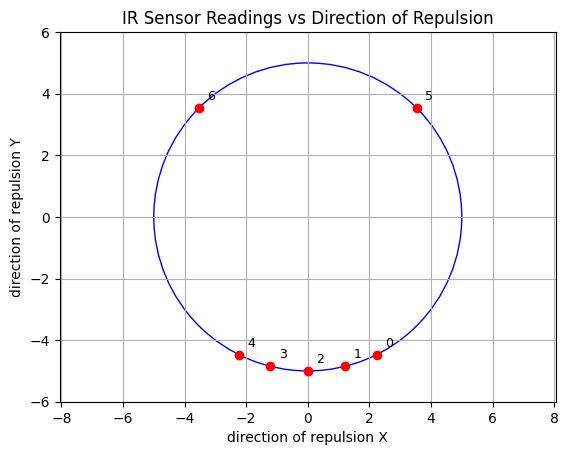

In [9]:
def direction_debug(sensor_data):
    print("IR sensors:", sensor_data)
    direction_repulsion = local_nav.compute(sensor_data, state=1)
    print("Direction of repulsion:", direction_repulsion)
    return direction_repulsion

sensor_data_list = 1000*np.eye(7)
for sensor_nb, sensor_data in enumerate(sensor_data_list):
    dir = local_nav.compute(sensor_data, state=1)
    # plot the point
    plt.plot(dir[0], dir[1], 'ro')
    # annotate the point with its sensor index (offset a few points to the right/up)
    plt.annotate(str(sensor_nb), (dir[0], dir[1]), textcoords='offset points', xytext=(6,6), fontsize=9)
# draw reference circle once
plt.gca().add_artist(plt.Circle((0.0, 0.0), 5.0, color='b', fill=False))
plt.xlabel('direction of repulsion X')
plt.ylabel('direction of repulsion Y')
plt.title('IR Sensor Readings vs Direction of Repulsion')
plt.axis('equal')
plt.xlim([-6, 6])
plt.ylim([-6, 6])
plt.grid()
plt.show()

In [10]:
def diff_robot_control(direction_repulsion, base_speed=0,k=5):
    x = direction_repulsion[0]
    y = direction_repulsion[1]
    left_speed = base_speed + k * (y + x)
    right_speed = base_speed + k * (y - x)
    return (int(left_speed), int(right_speed))



In [ ]:
while True:
    spd = diff_robot_control(local_nav.compute(robot_get_ir(), state=1))
    robot.set_speed(spd[0], spd[1])
    # delay 1s
    time.sleep(0.2)

KeyboardInterrupt: 

In [ ]:
robot.stop()

# Global Navigation

smooth_path = [(2, 2), (80, 60), (99, 86), (99, 99)]


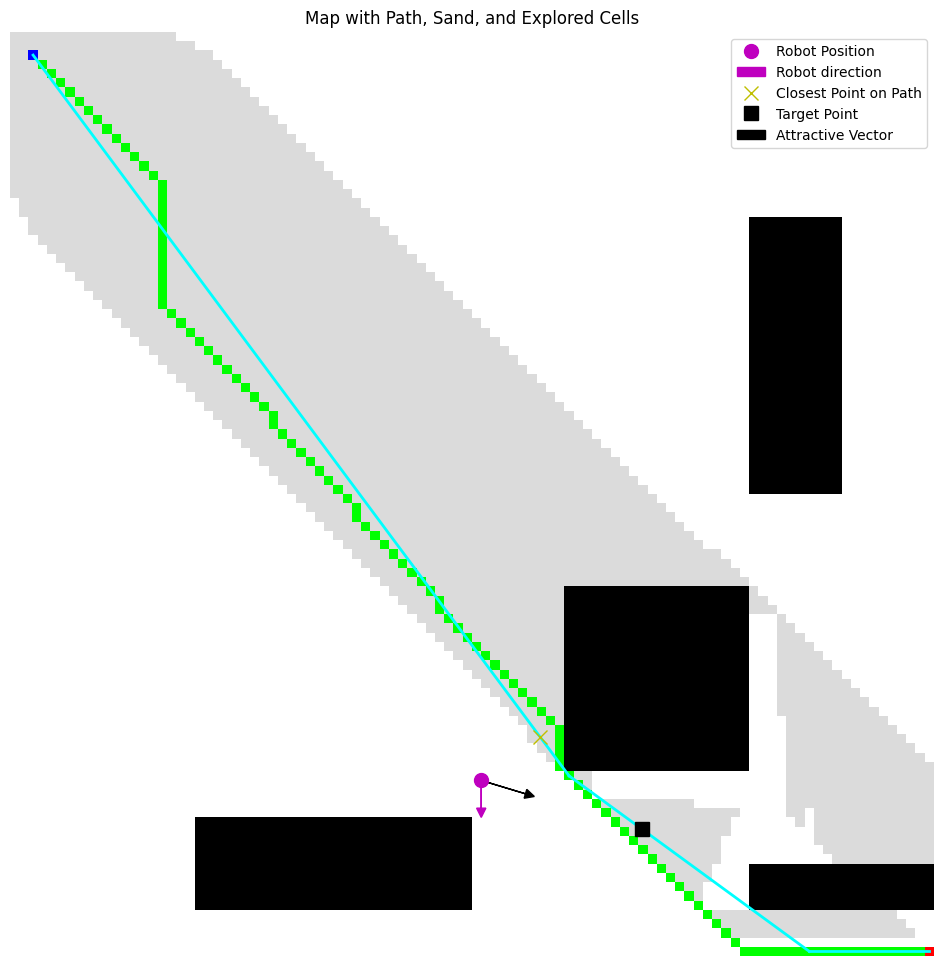

In [16]:
path8, explored8, op8 = global_nav.grid_search_astar(global_nav.Map100, global_nav.SearchStart, global_nav.SearchGoal)
smooth_path = global_nav.grid_path_smoothing(path8, global_nav.Map100)
print("smooth_path =", smooth_path)
robot_pose = (80.5, 50.5,np.pi/2)
closest_point = global_nav.find_closest_point_smoothed_path(robot_pose[:2], smooth_path)
target_point = global_nav.target_point(closest_point, look_ahead_distance=15.0, path=smooth_path)
attractive_vector = global_nav.direction_attraction(robot_pose[:2], target_point)
if path8:
    global_nav.display_map(global_nav.Map100, path8, 
                           global_nav.SearchStart, 
                           global_nav.SearchGoal, 
                           explored8, smooth_path, 
                           robot_pose=robot_pose, 
                           closest_point=closest_point, 
                           target_point=target_point,
                           attractive_vector=attractive_vector)
else:
    print("No path found with A* (8-connected)")

# Control

#### Disconnect robot

In [ ]:
# TODO:
await tdmclient.notebook.stop()
print("Disconnected from Thymio")

Disconnected from Thymio
